In [57]:
# %load_ext autoreload
# %autoreload 2

In [58]:
from tf_keras import backend as K
import tensorflow as tf

tf.random.set_seed(0)

In [59]:
import math
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

In [60]:
#@title custom_callbacks.py
%%writefile custom_callbacks.py
from tf_keras.callbacks import Callback
import math
import numpy as np
import tensorflow as tf
from tf_keras import backend as K
import matplotlib.pyplot as plt
from pathlib import Path
import os

def save_weights(model, file):
  model.save_weights(file, overwrite=True)

def reset_weights(model, file):
  model.load_weights(file)

  return model


class CycleLearner(Callback):
  def __init__(self, lr, nb, n_cycle, cycle_len=1, cycle_mult=1,
                snapshots=False, n_snapshots=5,
                snapshots_name='temp_model', snapshots_folder='snapshots'):
    self.lr = lr
    self.nb = nb*cycle_len
    self.n_cycle = n_cycle
    self.cycle_len = cycle_len
    self.cycle_mult = cycle_mult
    self.snapshots = snapshots
    self.n_snapshots = n_snapshots
    self.start_snaps = n_cycle - n_snapshots
    self.snapshots_name = snapshots_name
    self.snapshots_folder = snapshots_folder
    self.lr_list = []
    self.losses = []
    self.iterations = []
    self.stopped_training_because_n_cycle_reached = False

    if not os.path.exists(self.snapshots_folder):
      os.mkdir(self.snapshots_folder)

  def on_train_begin(self, logs={}):
    self.iteration,self.epoch = 0,0
    self.cycle_iter,self.cycle_count=0,0
    self.update_lr()

  def on_epoch_end(self, epoch, logs=None):
    self.epoch += 1

  def on_batch_end(self, batch, logs={}):
    self.iteration += 1
    self.lr_list.append(K.eval(self.model.optimizer.lr))
    loss = logs.get('loss')
    self.losses.append(loss)
    self.iterations.append(self.iteration)
    self.update_lr()
    if self.cycle_count == self.n_cycle:
      self.stopped_training_because_n_cycle_reached = True
      self.model.stop_training = True

  def on_cycle_end(self):
    self.cycle_iter = 0
    self.nb *= self.cycle_mult
    self.cycle_count += 1
    if self.snapshots and self.cycle_count>self.start_snaps:
      file_name = self.snapshots_folder +  '/'+ f'{self.snapshots_name}_{self.cycle_count}.weights.h5'
      save_weights(self.model, file_name)

  def update_lr(self):
    new_lr = self.calc_lr()
    K.set_value(self.model.optimizer.lr, new_lr)

  def calc_lr(self):
    if self.iteration < self.nb/20:
      self.cycle_iter += 1
      return self.lr/100.

    cos_out = np.cos(np.pi*(self.cycle_iter)/self.nb) + 1
    self.cycle_iter += 1
    if self.cycle_iter==self.nb:
      self.on_cycle_end()

    return self.lr / 2 * cos_out

  def on_train_end(self, logs=None):
    if self.stopped_training_because_n_cycle_reached:
      print("Stopped training because {} cycles were reached".format(self.n_cycle), flush=True)

  def plot_loss(self, skip=10):
    plt.xlabel("steps")
    plt.ylabel("loss")
    plt.plot(self.iterations[skip:], self.losses[skip:])

  def plot_lr(self):
    plt.xlabel("steps")
    plt.ylabel("learning rate")
    plt.plot(self.iterations, self.lr_list)


class LrFinder(Callback):
  def __init__(self, nb, start_lr=1e-5, end_lr=10):
    self.start_lr = start_lr
    self.lr = start_lr
    self.lr_mult = (end_lr/start_lr)**(1/nb)
    self.lr_list = []
    self.losses = []
    self.iterations = []
    self.derivatives = []
    self.stopped_training_because_nan = False
    self.stopped_training_because_suddenly_increases_too_much = False
    self.stop_at_batch = 0

  def on_train_begin(self, logs=None):
    self.best = 1e9
    self.iteration = 0
    self.update_lr()

  def update_lr(self):
    new_lr = self.start_lr * (self.lr_mult**self.iteration)
    K.set_value(self.model.optimizer.lr, new_lr)

  def on_train_batch_end(self, batch, logs=None):
    loss = logs.get("loss")
    self.iteration += 1

    self.lr_list.append(K.eval(self.model.optimizer.lr))
    self.losses.append(loss)
    self.iterations.append(self.iteration)

    if math.isnan(loss):
      self.stopped_training_because_nan  = True
      self.stop_at_batch = batch + 1
      self.model.stop_training = True

    if loss > self.best*4:
      self.stopped_training_because_suddenly_increases_too_much = True
      self.stop_at_batch = batch + 1
      self.model.stop_training = True

    if loss < self.best:
      self.best = loss

    self.update_lr()

  def on_train_end(self, logs=None):
    if self.stopped_training_because_nan:
      print("Stopped training at batch {} because the loss was nan".format(self.stop_at_batch), flush=True)

    if self.stopped_training_because_suddenly_increases_too_much:
      print("Stopped training at batch {} because the loss suddenly increases too much".format(self.stop_at_batch), flush=True)

  def plot_loss(self, skip=10):
    plt.xlabel("steps")
    plt.ylabel("loss")
    plt.plot(self.iterations[skip:], self.losses[skip:])

  def plot_lr(self):
    plt.xlabel("steps")
    plt.ylabel("learning rate")
    plt.plot(self.iterations, self.lr_list)

  def plot(self, use_log_scale=True, n_skip_start=2, xlim=None, ylim=None):
    plt.ylabel("loss")
    plt.xlabel("learning rate (log scale)")
    plt.plot(self.lr_list[n_skip_start:], self.losses[n_skip_start:])

    if use_log_scale:
      plt.xscale("log")
    if ylim is not None: plt.ylim(top=ylim)
    if xlim is not None: plt.xlim(right=xlim)

  def plot_loss_variation(self, window_size=1, xlim_range=None, ylim_range=None):
    '''
    Parameters:
      xlim_range - range used to obtain the learning rate values
      window_size - number of batches for simple moving average to smooth out the curve.
    '''
    assert (xlim_range!=None), "The parameter 'xlim_range' should be different from None"
    assert (window_size>0), "The parameter 'window_size' should be greater than 0"

    self.derivatives = []
    self.lr_list_on_xlim = []
    for i in range(len(self.lr_list)-window_size):
      if self.lr_list[i] < xlim_range[0]:
        continue
      if self.lr_list[i] > xlim_range[1]:
        break
      derivative = (self.losses[i + window_size] - self.losses[i]) / window_size
      self.derivatives.append(derivative)
      self.lr_list_on_xlim.append(self.lr_list[i])

    plt.ylabel("d/loss")
    plt.xlabel("learning rate (log scale)")
    plt.plot(self.lr_list_on_xlim, self.derivatives)
    plt.xscale('log')
    if ylim_range is not None: plt.ylim(ylim_range)
    if xlim_range is not None: plt.xlim(xlim_range)

Overwriting custom_callbacks.py


# MNIST

http://yann.lecun.com/exdb/mnist/

Base de datos de digitos escritos a mano.

* 60,000 imágenes de entrenamiento.
* 10,000 imágenes de test.

Cada imagen es de 28x28, en escala de grises.

In [61]:
from tf_keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [62]:
print(f'Train -> x: {x_train.shape}')
print(f'         y: {y_train.shape}')
print(f'Test ->  x: {x_test.shape}')
print(f'         y: {y_test.shape}')

Train -> x: (60000, 28, 28)
         y: (60000,)
Test ->  x: (10000, 28, 28)
         y: (10000,)


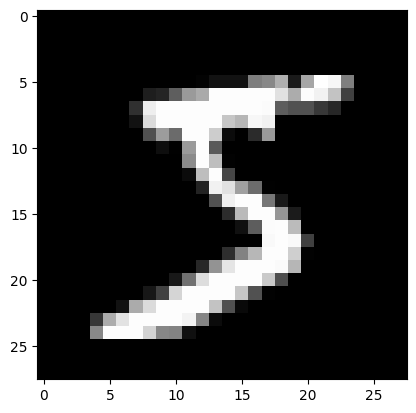

In [63]:
# Veamos una muestra
plt.imshow(x_train[0], 'gray');

In [64]:
y_train[0]

np.uint8(5)

In [65]:
# Veamos todas las clases del conjunto de entrenamiento
set(y_train)

{np.uint8(0),
 np.uint8(1),
 np.uint8(2),
 np.uint8(3),
 np.uint8(4),
 np.uint8(5),
 np.uint8(6),
 np.uint8(7),
 np.uint8(8),
 np.uint8(9)}

## Ajustamos las dimensiones de las imágenes

Para usar las imágenes en una multiplicación de matrices, esta necesita tener sólo 2 dimensiones.

In [66]:
x_train.shape

(60000, 28, 28)

In [67]:
x_train = x_train.reshape([-1, 28*28])
x_test = x_test.reshape([-1, 28*28])

x_train.shape, x_test.shape

((60000, 784), (10000, 784))

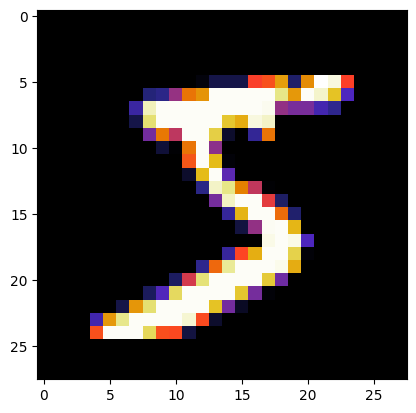

In [68]:
# Podemos usar el reshape de nuevo, para mostrar la imagen
plt.imshow(x_train[0].reshape([28,28]), 'CMRmap');

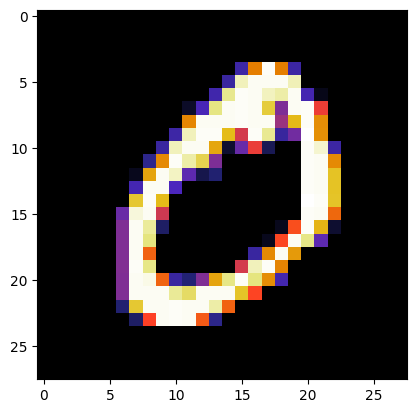

In [69]:
plt.imshow(x_train[1].reshape([28,28]), cmap='CMRmap');

## Definimos un modelo

In [70]:
%mkdir -p my_model

In [71]:
from tf_keras.models import Sequential
from tf_keras.layers import Dense
from tf_keras.optimizers import SGD

from custom_callbacks import save_weights

def create_model():
  K.clear_session()

  model = Sequential([
      Dense(128, activation='relu', input_shape=(784,)),
      Dense(64, activation='relu'),
      Dense(10, activation='softmax')
  ])

  return model

In [72]:
lr = 0.01

model = create_model()

model.compile(optimizer=SGD(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# La función de pérdida 'sparse_categorical_crossentropy' realiza automaticamente la conversión
# del target a one-hot encoding.

In [73]:
# Guardamos los pesos del modelo para poder usarlos posteriormente al re-inicializar los pesos
save_weights(model, 'my_model/model.weights.h5')

In [74]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               100480    
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dense_2 (Dense)             (None, 10)                650       
                                                                 
Total params: 109386 (427.29 KB)
Trainable params: 109386 (427.29 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [75]:
bs = 256
nb = math.ceil(len(x_train)/bs) # Nro de batches

## Usemos el método de Learning rate finder

In [76]:
from custom_callbacks import LrFinder

lr_finder = LrFinder(nb)

model.fit(x_train, y_train, batch_size=bs, callbacks=[lr_finder])

235/235 [==============================] - 1s 4ms/step - loss: 877.0566 - accuracy: 0.4528
Stopped training at batch 140 because the loss suddenly increases too much


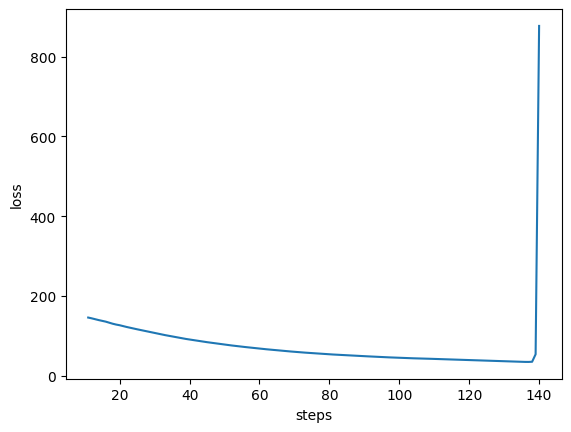

In [77]:
lr_finder.plot_loss()

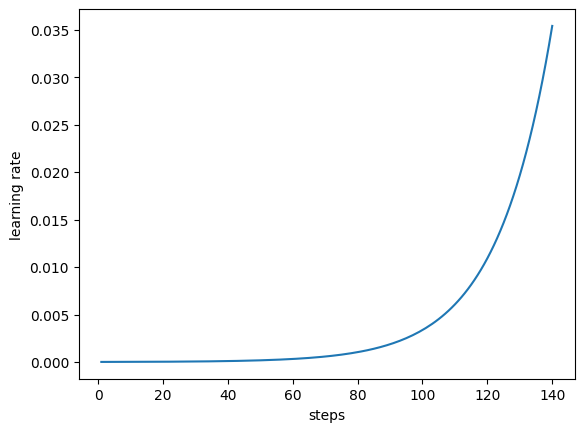

In [78]:
lr_finder.plot_lr()

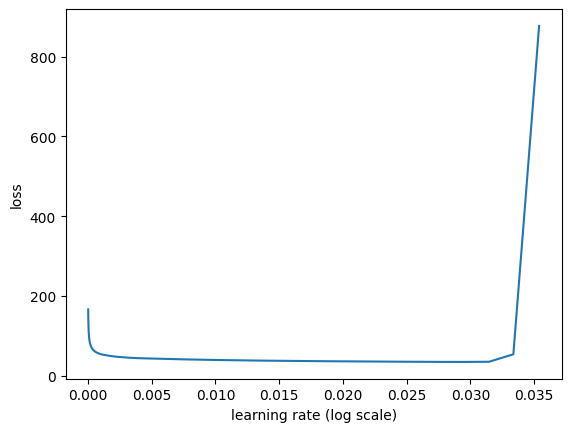

In [79]:
#Necesitamos seleccionar un punto donde el loss disminuya más rápido
lr_finder.plot(use_log_scale=False)

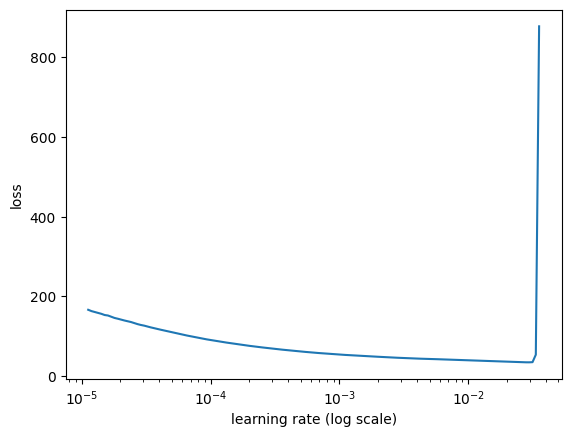

In [80]:
#Necesitamos seleccionar un punto donde el loss disminuya más rápido
lr_finder.plot(use_log_scale=True)

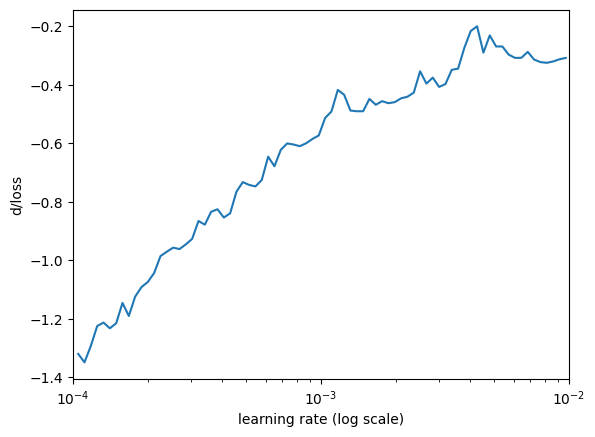

In [81]:
#d/loss es derivada del loss

#window_size - number of batches for simple moving average to smooth out the curve.
window_size = 1
#You can modify the range to adapt your plot
xlim_range=[1e-4, 1e-2]

lr_finder.plot_loss_variation(window_size=window_size, xlim_range=xlim_range)

In [82]:
index_of_the_min_derivative = np.argmin(lr_finder.derivatives)

lr = lr_finder.lr_list_on_xlim[index_of_the_min_derivative]

lr = lr.item()

lr

0.00011138033005408943

### Entrenamiento

In [83]:
from custom_callbacks import reset_weights

model = create_model()

model.compile(SGD(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Reseteamos los pesos y compilamos el modelo con el nuevo lr porque la variable ya fue sobreescrita
model = reset_weights(model, 'my_model/model.weights.h5')

In [84]:
log = model.fit(x_train, y_train, batch_size=bs, epochs=6, validation_data=(x_test, y_test))

Epoch 1/6
235/235 [==============================] - 2s 7ms/step - loss: 13.4292 - accuracy: 0.6255 - val_loss: 5.0187 - val_accuracy: 0.7629
Epoch 2/6
235/235 [==============================] - 2s 7ms/step - loss: 4.2262 - accuracy: 0.7867 - val_loss: 3.3890 - val_accuracy: 0.8142
Epoch 3/6
235/235 [==============================] - 3s 11ms/step - loss: 3.0947 - accuracy: 0.8229 - val_loss: 2.7229 - val_accuracy: 0.8359
Epoch 4/6
235/235 [==============================] - 4s 16ms/step - loss: 2.5277 - accuracy: 0.8397 - val_loss: 2.3408 - val_accuracy: 0.8475
Epoch 5/6
235/235 [==============================] - 3s 13ms/step - loss: 2.1742 - accuracy: 0.8513 - val_loss: 2.0671 - val_accuracy: 0.8595
Epoch 6/6
235/235 [==============================] - 3s 11ms/step - loss: 1.9227 - accuracy: 0.8611 - val_loss: 1.8868 - val_accuracy: 0.8650


In [85]:
def show_results(model, log):
    loss, acc = model.evaluate(x_test, y_test, batch_size=512, verbose=False)
    print(f'Loss     = {loss:.4f}')
    print(f'Accuracy = {acc:.4f}')

    val_loss = log.history['val_loss']
    val_acc = log.history['val_accuracy']

    fig, axes = plt.subplots(1, 2, figsize=(14,4))
    ax1, ax2 = axes
    ax1.plot(log.history['loss'], label='train')
    ax1.plot(val_loss, label='test')
    ax1.set_xlabel('epoch'); ax1.set_ylabel('loss')
    ax2.plot(log.history['accuracy'], label='train')
    ax2.plot(val_acc, label='test')
    ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy')
    for ax in axes: ax.legend()

Loss     = 1.8868
Accuracy = 0.8650


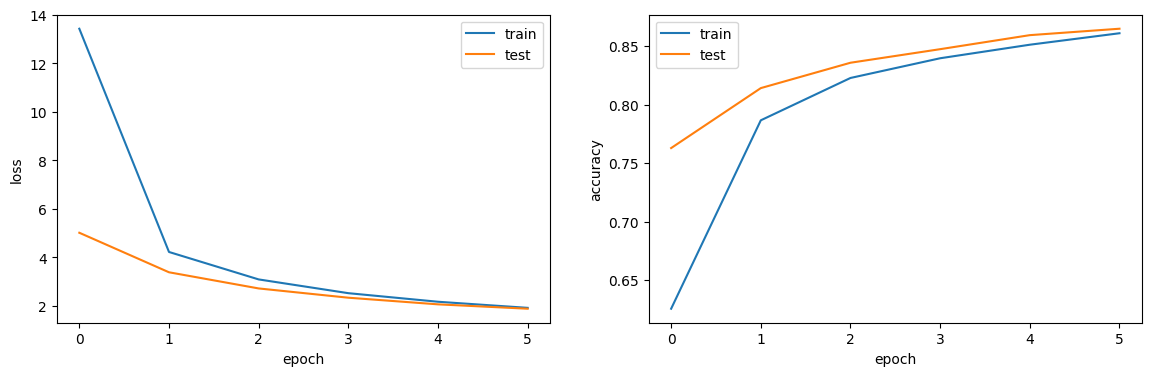

In [86]:
show_results(model, log)

## Cycling learning rates

In [87]:
from custom_callbacks import CycleLearner

cycle_learner = CycleLearner(lr, nb, n_cycle=3)

### Entrenamiento

In [88]:
from custom_callbacks import reset_weights

model = create_model()

model.compile(SGD(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model = reset_weights(model, 'my_model/model.weights.h5')

log = model.fit(x_train, y_train, batch_size=bs, epochs=100,
                validation_data=(x_test, y_test), callbacks=[cycle_learner])
# Nota: la cantidad de épocas la va a controlar el callback. Cada ciclo es igual a la cantidad de batchs (nb)

Epoch 1/100
235/235 [==============================] - 3s 8ms/step - loss: 22.9043 - accuracy: 0.5637 - val_loss: 8.0553 - val_accuracy: 0.6795
Epoch 2/100
235/235 [==============================] - 3s 12ms/step - loss: 6.1195 - accuracy: 0.7329 - val_loss: 5.1567 - val_accuracy: 0.7603
Epoch 3/100
235/235 [==============================] - 3s 14ms/step - loss: 4.5133 - accuracy: 0.7795 - val_loss: 4.0497 - val_accuracy: 0.7922
Stopped training because 3 cycles were reached


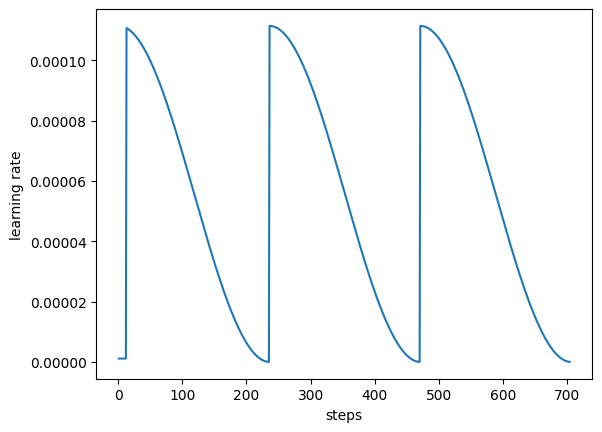

In [89]:
cycle_learner.plot_lr()

Loss     = 4.0497
Accuracy = 0.7922


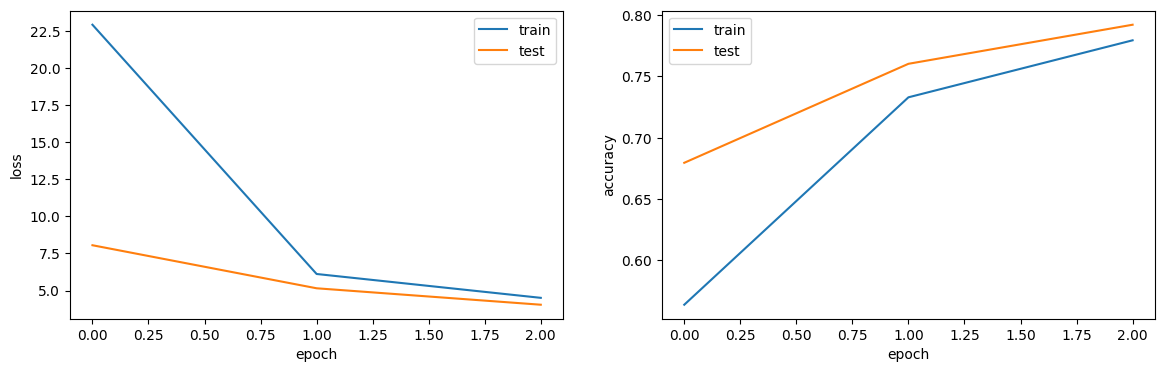

In [90]:
show_results(model, log)

In [91]:
from custom_callbacks import reset_weights

# El parametro "cycle_mult" permite que cada ciclo sea mayor al anterior,
# en este caso el doble del anterior

model = create_model()

model.compile(SGD(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model = reset_weights(model, 'my_model/model.weights.h5')

cycle_learner = CycleLearner(lr/2, nb, n_cycle=3, cycle_mult=2)
log = model.fit(x_train, y_train, batch_size=bs, epochs=100,
                validation_data=(x_test, y_test), callbacks=[cycle_learner])

Epoch 1/100
235/235 [==============================] - 4s 15ms/step - loss: 30.4099 - accuracy: 0.4590 - val_loss: 12.6097 - val_accuracy: 0.5759
Epoch 2/100
235/235 [==============================] - 4s 17ms/step - loss: 8.8645 - accuracy: 0.6620 - val_loss: 6.5624 - val_accuracy: 0.7197
Epoch 3/100
235/235 [==============================] - 2s 6ms/step - loss: 6.4047 - accuracy: 0.7240 - val_loss: 6.0480 - val_accuracy: 0.7339
Epoch 4/100
235/235 [==============================] - 2s 7ms/step - loss: 5.3879 - accuracy: 0.7537 - val_loss: 4.5224 - val_accuracy: 0.7777
Epoch 5/100
235/235 [==============================] - 1s 6ms/step - loss: 4.3256 - accuracy: 0.7859 - val_loss: 3.9318 - val_accuracy: 0.7962
Epoch 6/100
235/235 [==============================] - 2s 6ms/step - loss: 3.8992 - accuracy: 0.7988 - val_loss: 3.7298 - val_accuracy: 0.8028
Epoch 7/100
235/235 [==============================] - 1s 6ms/step - loss: 3.7769 - accuracy: 0.8027 - val_loss: 3.6988 - val_accuracy: 0.

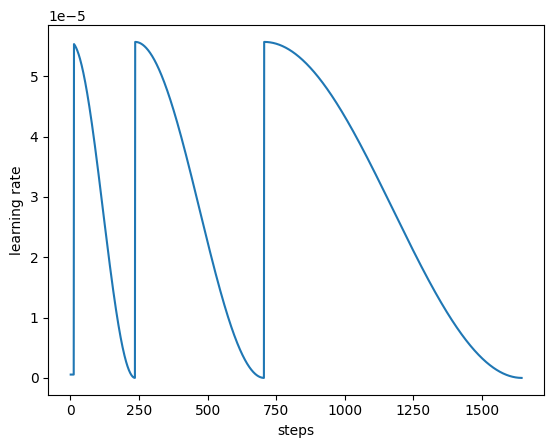

In [92]:
cycle_learner.plot_lr()

Loss     = 3.6988
Accuracy = 0.8043


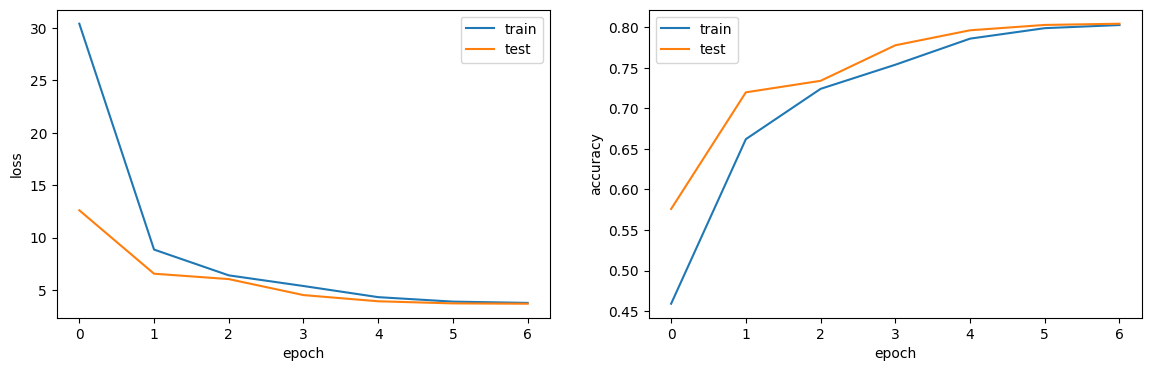

In [93]:
show_results(model, log)

In [94]:
from custom_callbacks import reset_weights

# El parametro "cycle_len" permite que cada ciclo sea N veces mayor,
# en este caso 2 veces más grande

model = create_model()

model.compile(SGD(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model = reset_weights(model, 'my_model/model.weights.h5')

cycle_learner = CycleLearner(lr/2, nb, n_cycle=3, cycle_len=2)
log = model.fit(x_train, y_train, batch_size=bs, epochs=100,
                validation_data=(x_test, y_test), callbacks=[cycle_learner])

Epoch 1/100
235/235 [==============================] - 3s 11ms/step - loss: 36.5238 - accuracy: 0.4641 - val_loss: 9.3434 - val_accuracy: 0.6530
Epoch 2/100
235/235 [==============================] - 2s 8ms/step - loss: 8.7373 - accuracy: 0.6638 - val_loss: 8.1054 - val_accuracy: 0.6787
Epoch 3/100
235/235 [==============================] - 2s 7ms/step - loss: 6.7373 - accuracy: 0.7150 - val_loss: 5.4955 - val_accuracy: 0.7500
Epoch 4/100
235/235 [==============================] - 2s 7ms/step - loss: 5.4286 - accuracy: 0.7515 - val_loss: 5.1691 - val_accuracy: 0.7591
Epoch 5/100
235/235 [==============================] - 2s 7ms/step - loss: 4.7847 - accuracy: 0.7717 - val_loss: 4.2239 - val_accuracy: 0.7857
Epoch 6/100
235/235 [==============================] - 2s 7ms/step - loss: 4.2151 - accuracy: 0.7881 - val_loss: 4.0735 - val_accuracy: 0.7889
Stopped training because 3 cycles were reached


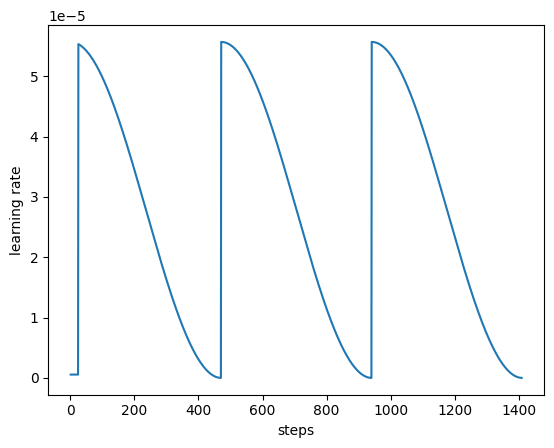

In [95]:
cycle_learner.plot_lr()

Loss     = 4.0735
Accuracy = 0.7889


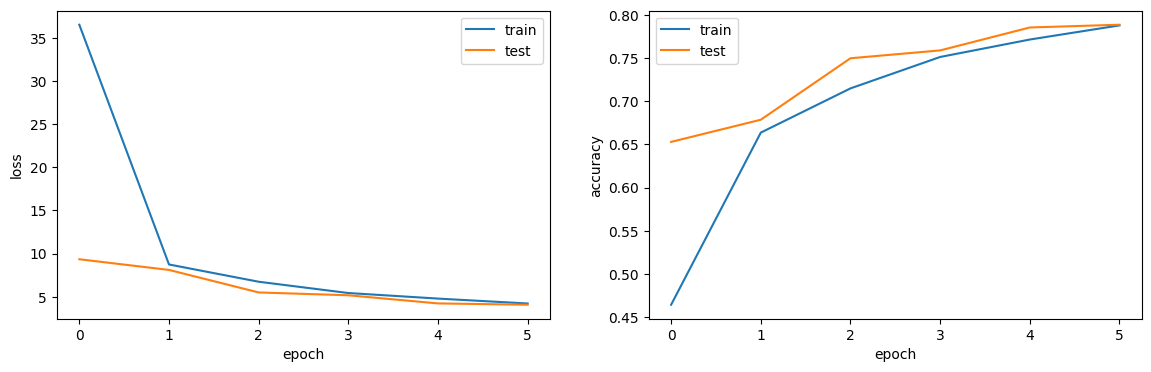

In [96]:
show_results(model, log)

## Snapshot ensembles

In [97]:
from custom_callbacks import reset_weights

# Iniciamos el entrenamiento de forma normal

model = create_model()

model.compile(SGD(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model = reset_weights(model, 'my_model/model.weights.h5')

cycle_learner = CycleLearner(lr, nb, n_cycle=5, cycle_mult=2)
log = model.fit(x_train, y_train, batch_size=bs, epochs=100,
                validation_data=(x_test, y_test), callbacks=[cycle_learner])

Epoch 1/100
235/235 [==============================] - 2s 7ms/step - loss: 22.9043 - accuracy: 0.5637 - val_loss: 8.0553 - val_accuracy: 0.6795
Epoch 2/100
235/235 [==============================] - 2s 7ms/step - loss: 5.8405 - accuracy: 0.7412 - val_loss: 4.3713 - val_accuracy: 0.7825
Epoch 3/100
235/235 [==============================] - 2s 10ms/step - loss: 4.2464 - accuracy: 0.7880 - val_loss: 4.0453 - val_accuracy: 0.7937
Epoch 4/100
235/235 [==============================] - 2s 9ms/step - loss: 3.6115 - accuracy: 0.8074 - val_loss: 3.0956 - val_accuracy: 0.8239
Epoch 5/100
235/235 [==============================] - 2s 6ms/step - loss: 2.8888 - accuracy: 0.8288 - val_loss: 2.6841 - val_accuracy: 0.8389
Epoch 6/100
235/235 [==============================] - 2s 6ms/step - loss: 2.5895 - accuracy: 0.8391 - val_loss: 2.5473 - val_accuracy: 0.8432
Epoch 7/100
235/235 [==============================] - 2s 6ms/step - loss: 2.4963 - accuracy: 0.8425 - val_loss: 2.5267 - val_accuracy: 0.84

Loss     = 1.1235
Accuracy = 0.8951


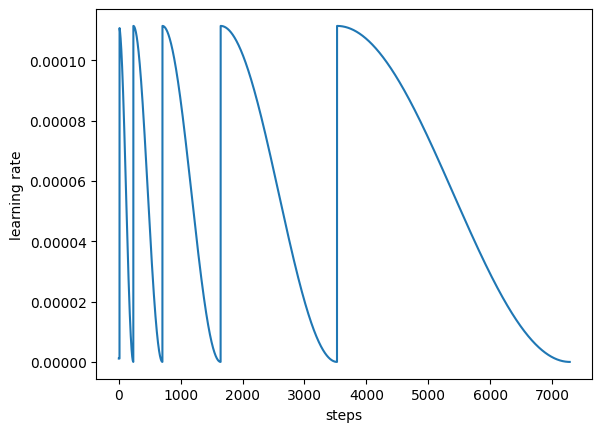

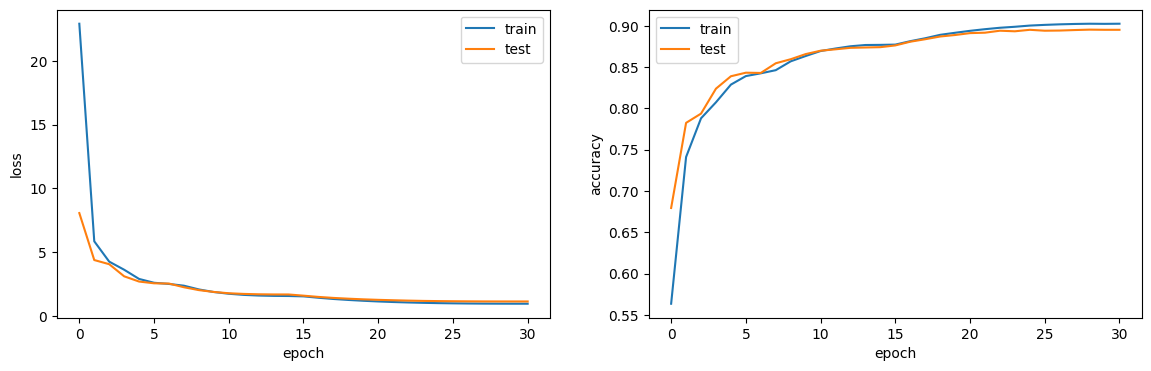

In [98]:
cycle_learner.plot_lr()
show_results(model, log)

In [99]:
# Ahora activamos los snapshots
cycle_learner = CycleLearner(lr/2, nb, n_cycle=3, snapshots=True, snapshots_name='mnist_test')
log = model.fit(x_train, y_train, batch_size=bs, epochs=100,
                validation_data=(x_test, y_test), callbacks=[cycle_learner])

Epoch 1/100
235/235 [==============================] - 2s 8ms/step - loss: 0.9466 - accuracy: 0.9017 - val_loss: 1.1160 - val_accuracy: 0.8955
Epoch 2/100
235/235 [==============================] - 3s 11ms/step - loss: 0.9374 - accuracy: 0.9026 - val_loss: 1.1055 - val_accuracy: 0.8960
Epoch 3/100
235/235 [==============================] - 2s 7ms/step - loss: 0.9259 - accuracy: 0.9034 - val_loss: 1.0959 - val_accuracy: 0.8968
Stopped training because 3 cycles were reached


Loss     = 1.0959
Accuracy = 0.8968


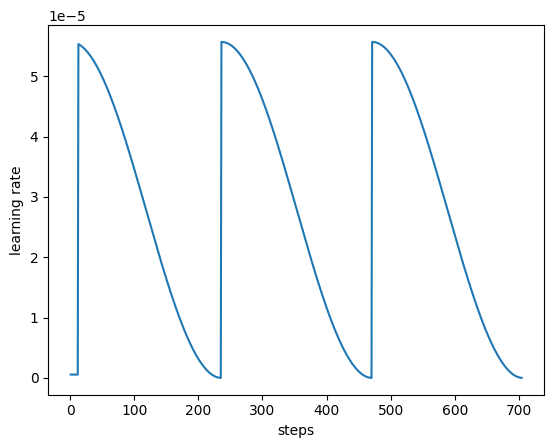

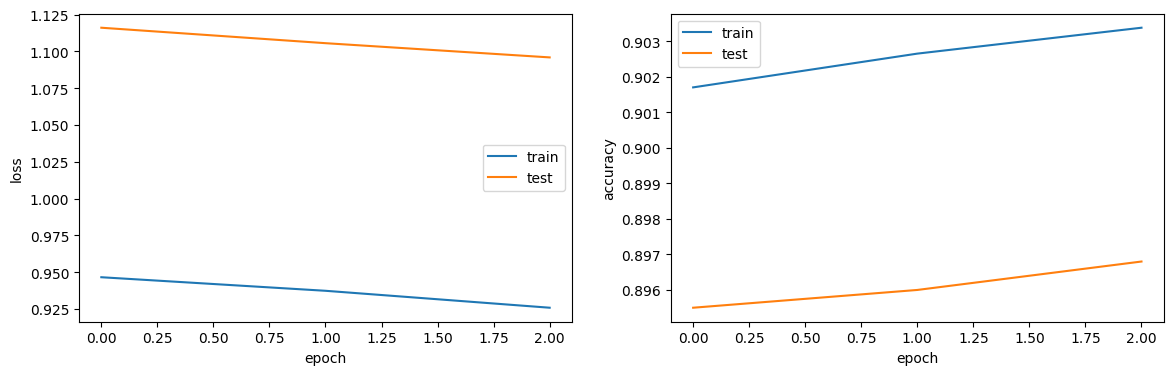

In [100]:
cycle_learner.plot_lr()
show_results(model, log)

In [101]:
# Veamos los archivos creados para los snapshots
snapshots = 'snapshots'
snapshots_file_names = list()

for snapshot_file in os.listdir(snapshots):
  snapshot_file_name = os.path.join(snapshots, snapshot_file)

  snapshots_file_names.append(snapshot_file_name)

  print(snapshot_file_name)

snapshots/mnist_test_3.weights.h5
snapshots/mnist_test_1.weights.h5
snapshots/mnist_test_2.weights.h5


In [102]:
# Veamos ahora usando snapshots
snapshots_results = np.zeros([10000,10])

for snapshot_file_name in snapshots_file_names:
  model = reset_weights(model, snapshot_file_name)

  snapshots_results += model.predict(x_test) / len(snapshots_file_names)

acc = (snapshots_results.argmax(axis=1) == y_test).mean()
print(f'Snapshot accuracy = {acc}')

313/313 [==============================] - 1s 2ms/step
Snapshot accuracy = 0.8956


## Test Optimizers

In [103]:
from tf_keras.optimizers import SGD, Adam, RMSprop, Adagrad

#Definición de los parámetros para compilar los modelos
learning_rate = lr
optimizers_names = ['sgd', 'adam', 'rmsprop', 'adagrad']
optimizers = [SGD(learning_rate), Adam(learning_rate), RMSprop(learning_rate), Adagrad(learning_rate)]

#Creación de los modelos
models = [create_model() for _ in range(len(optimizers_names))]

#Compilar los modelos
for model, optimizer in zip(models, optimizers):
  model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

#Reseteamos los pesos
models = [reset_weights(model, 'my_model/model.weights.h5') for model in models]

In [104]:
#Entrenamiento de los modelos
histories = list()

for optimizer_name, model in zip(optimizers_names, models):
  print("Training for optimizer {}".format(optimizer_name), flush=True)
  histories.append(model.fit(x_train, y_train, batch_size=bs, epochs=10, validation_data=(x_test, y_test)))
  print(flush=True)

Training for optimizer sgd
Epoch 1/10
235/235 [==============================] - 3s 10ms/step - loss: 13.4292 - accuracy: 0.6255 - val_loss: 5.0187 - val_accuracy: 0.7629
Epoch 2/10
235/235 [==============================] - 2s 8ms/step - loss: 4.2262 - accuracy: 0.7867 - val_loss: 3.3890 - val_accuracy: 0.8142
Epoch 3/10
235/235 [==============================] - 1s 6ms/step - loss: 3.0947 - accuracy: 0.8229 - val_loss: 2.7229 - val_accuracy: 0.8359
Epoch 4/10
235/235 [==============================] - 1s 6ms/step - loss: 2.5277 - accuracy: 0.8397 - val_loss: 2.3408 - val_accuracy: 0.8475
Epoch 5/10
235/235 [==============================] - 1s 6ms/step - loss: 2.1742 - accuracy: 0.8513 - val_loss: 2.0671 - val_accuracy: 0.8595
Epoch 6/10
235/235 [==============================] - 1s 6ms/step - loss: 1.9227 - accuracy: 0.8611 - val_loss: 1.8868 - val_accuracy: 0.8650
Epoch 7/10
235/235 [==============================] - 1s 6ms/step - loss: 1.7310 - accuracy: 0.8673 - val_loss: 1.7254 

In [105]:
def plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, legend):
  plt.figure(figsize=(10, 6))
  plt.axis(axis)

  for history in histories:
    plt.plot(history.history[metric])

  plt.title(title)
  plt.ylabel(y_label)
  plt.xlabel(x_label)
  plt.legend(legend, loc='lower right')
  plt.show()

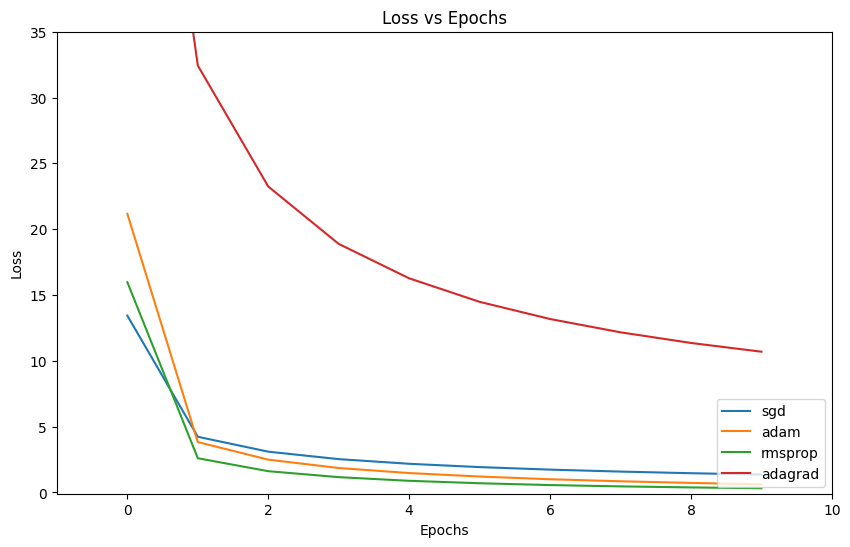

In [106]:
axis = (-1, 10, -0.1, 35)
metric = 'loss'
title = 'Loss vs Epochs'
y_label = 'Loss'
x_label = 'Epochs'

plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, optimizers_names)

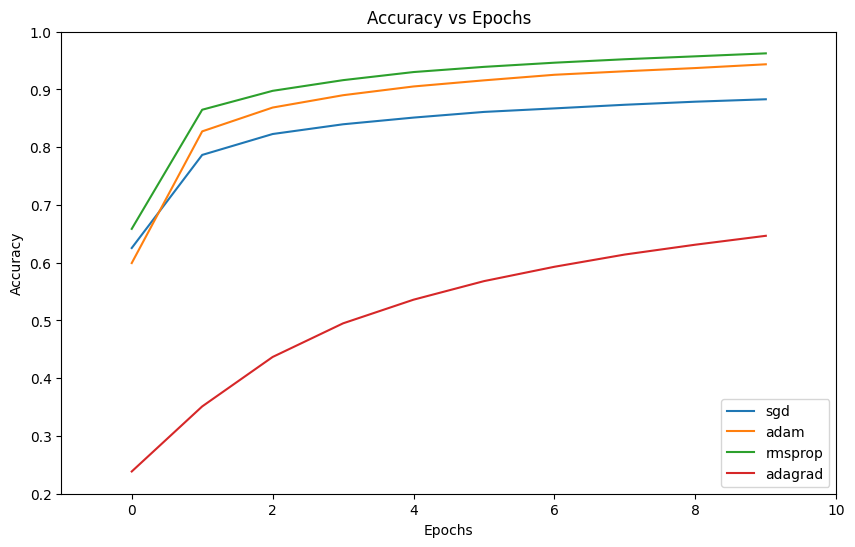

In [107]:
axis = (-1, 10, 0.2, 1)
metric = 'accuracy'
title = 'Accuracy vs Epochs'
y_label = 'Accuracy'
x_label = 'Epochs'

plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, optimizers_names)

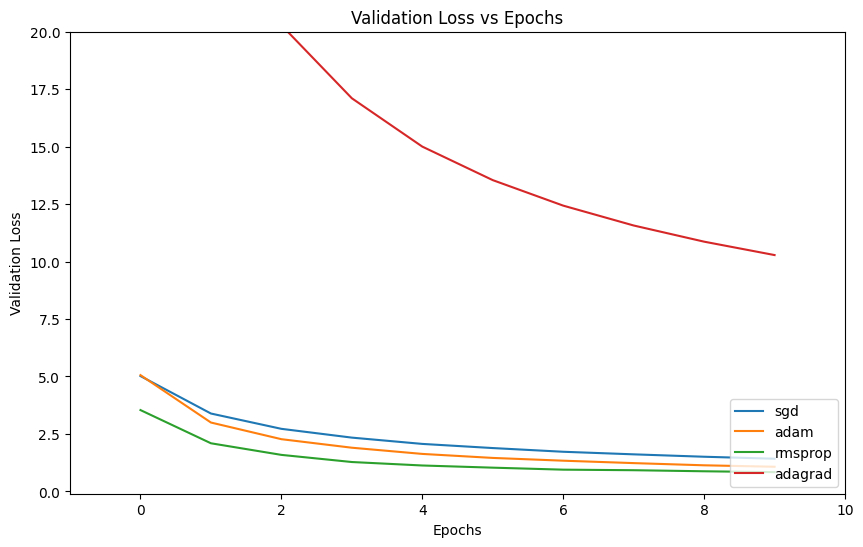

In [108]:
axis = (-1, 10, -0.1, 20)
metric = 'val_loss'
title = 'Validation Loss vs Epochs'
y_label = 'Validation Loss'
x_label = 'Epochs'

plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, optimizers_names)

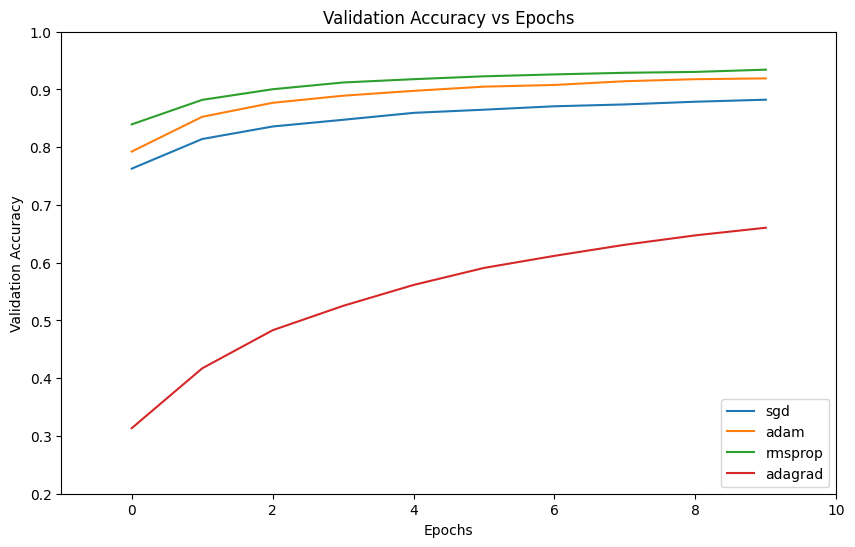

In [109]:
axis = (-1, 10, 0.2, 1)
metric = 'val_accuracy'
title = 'Validation Accuracy vs Epochs'
y_label = 'Validation Accuracy'
x_label = 'Epochs'

plot_history_with_optimizers(axis, histories, metric, title, y_label, x_label, optimizers_names)

# Ejercicio

Variar la arquitectura de la red y experimentar con las técnicas vistas en clase:
* Weight initialization.
* Weight regularization.
* Regularización (Dropout, BatchNormalization).
* Distintos algoritmos de optimización.

In [110]:
from tf_keras.models import Sequential
from tf_keras.layers import Dense, Dropout, BatchNormalization
from tf_keras.initializers import HeNormal
from tf_keras.regularizers import l2
from tf_keras import backend as K

def create_advanced_model(l2_rate=0.001, dropout_rate=0.3):
    K.clear_session()

    model = Sequential([
        # Capa de entrada con inicialización HeNormal y regularización L2
        Dense(256, activation='relu', kernel_initializer=HeNormal(),
              kernel_regularizer=l2(l2_rate), input_shape=(784,)),
        BatchNormalization(),
        Dropout(dropout_rate),

        # Segunda capa oculta
        Dense(128, activation='relu', kernel_initializer=HeNormal(),
              kernel_regularizer=l2(l2_rate)),
        BatchNormalization(),
        Dropout(dropout_rate),

        # Capa de salida
        Dense(10, activation='softmax')
    ])

    return model

model_exercise = create_advanced_model()
model_exercise.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               200960    
                                                                 
 batch_normalization (Batch  (None, 256)               1024      
 Normalization)                                                  
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 batch_normalization_1 (Bat  (None, 128)               512       
 chNormalization)                                                
                                                                 
 dropout_1 (Dropout)         (None, 128)               0

In [111]:
from tf_keras.optimizers import Adam

# Configuración del optimizador y compilación
opt = Adam(learning_rate=0.001)
model_exercise.compile(optimizer=opt,
                        loss='sparse_categorical_crossentropy',
                        metrics=['accuracy'])

# Guardar pesos iniciales
save_weights(model_exercise, 'my_model/advanced_model.weights.h5')

# Entrenamiento
history_exercise = model_exercise.fit(
    x_train, y_train,
    batch_size=bs,
    epochs=15,
    validation_data=(x_test, y_test)
)

Epoch 1/15
235/235 [==============================] - 4s 14ms/step - loss: 0.9362 - accuracy: 0.8801 - val_loss: 0.5805 - val_accuracy: 0.9530
Epoch 2/15
235/235 [==============================] - 4s 17ms/step - loss: 0.5324 - accuracy: 0.9464 - val_loss: 0.4036 - val_accuracy: 0.9676
Epoch 3/15
235/235 [==============================] - 3s 13ms/step - loss: 0.3889 - accuracy: 0.9587 - val_loss: 0.3087 - val_accuracy: 0.9725
Epoch 4/15
235/235 [==============================] - 4s 18ms/step - loss: 0.3061 - accuracy: 0.9649 - val_loss: 0.2491 - val_accuracy: 0.9737
Epoch 5/15
235/235 [==============================] - 3s 13ms/step - loss: 0.2594 - accuracy: 0.9657 - val_loss: 0.2290 - val_accuracy: 0.9725
Epoch 6/15
235/235 [==============================] - 4s 18ms/step - loss: 0.2301 - accuracy: 0.9683 - val_loss: 0.2085 - val_accuracy: 0.9725
Epoch 7/15
235/235 [==============================] - 3s 13ms/step - loss: 0.2151 - accuracy: 0.9693 - val_loss: 0.1944 - val_accuracy: 0.9741

Loss     = 0.1548
Accuracy = 0.9777


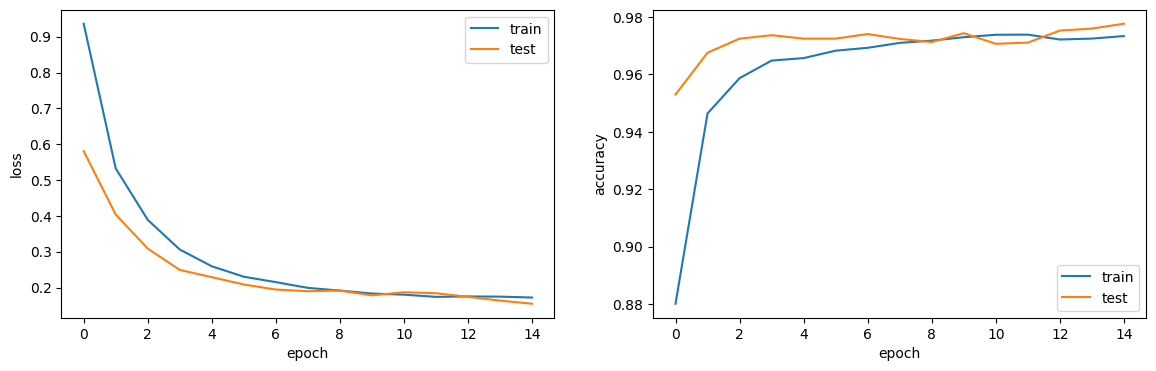

In [112]:
show_results(model_exercise, history_exercise)

# Otra base de datos para practicar:

``` python
from tf_keras.datasets import fashion_mnist

from tf_keras.models import Sequential
from tf_keras.layers import Dense, Dropout
from tf_keras.initializers import RandomNormal, Zeros
from tf_keras.optimizers import SGD

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

.
.
.

def create_model():
  K.clear_session()

  model = Sequential([
    Dense(..., activation='relu', kernel_initializer=RandomNormal(stddev=0.01), bias_initializer=Zeros(), input_shape=(...,)),
    Dropout(rate=0.2),
    Dense(..., activation='relu'),
    Dropout(rate=0.2),
    Dense(..., activation='softmax')
  ])

  return model
.
.
.
```

In [113]:
from tf_keras.datasets import fashion_mnist

# Carga de datos
(x_train_fashion, y_train_fashion), (x_test_fashion, y_test_fashion) = fashion_mnist.load_data()

# Normalización y cambio de dimensión (a plano 784)
x_train_fashion = x_train_fashion.reshape([-1, 28 * 28]).astype('float32') / 255.0
x_test_fashion = x_test_fashion.reshape([-1, 28 * 28]).astype('float32') / 255.0

print(f"Fashion MNIST Train x: {x_train_fashion.shape}, y: {y_train_fashion.shape}")
print(f"Fashion MNIST Test x:  {x_test_fashion.shape}, y: {y_test_fashion.shape}")

Fashion MNIST Train x: (60000, 784), y: (60000,)
Fashion MNIST Test x:  (10000, 784), y: (10000,)


In [114]:
from tf_keras.models import Sequential
from tf_keras.layers import Dense, Dropout
from tf_keras.initializers import RandomNormal, Zeros
from tf_keras import backend as K

def create_fashion_model():
    K.clear_session()

    model = Sequential([
        Dense(256, activation='relu',
              kernel_initializer=RandomNormal(stddev=0.01),
              bias_initializer=Zeros(),
              input_shape=(784,)),
        Dropout(rate=0.2),
        Dense(128, activation='relu',
              kernel_initializer=RandomNormal(stddev=0.01),
              bias_initializer=Zeros()),
        Dropout(rate=0.2),
        Dense(10, activation='softmax')
    ])

    return model

fashion_model = create_fashion_model()
fashion_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               200960    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_2 (Dense)             (None, 10)                1290      
                                                                 
Total params: 235146 (918.54 KB)
Trainable params: 235146 (918.54 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [115]:
from tf_keras.optimizers import SGD

lr_fashion = 0.01

fashion_model = create_fashion_model()
fashion_model.compile(optimizer=SGD(learning_rate=lr_fashion, momentum=0.9),
                      loss='sparse_categorical_crossentropy',
                      metrics=['accuracy'])

# Guardar pesos iniciales
save_weights(fashion_model, 'my_model/fashion_model.weights.h5')

# Entrenamiento
bs_fashion = 256
history_fashion = fashion_model.fit(
    x_train_fashion, y_train_fashion,
    batch_size=bs_fashion,
    epochs=15,
    validation_data=(x_test_fashion, y_test_fashion)
)

Epoch 1/15
235/235 [==============================] - 9s 34ms/step - loss: 1.1446 - accuracy: 0.5856 - val_loss: 0.6698 - val_accuracy: 0.7589
Epoch 2/15
235/235 [==============================] - 6s 25ms/step - loss: 0.6049 - accuracy: 0.7895 - val_loss: 0.5342 - val_accuracy: 0.8119
Epoch 3/15
235/235 [==============================] - 7s 30ms/step - loss: 0.5115 - accuracy: 0.8210 - val_loss: 0.4822 - val_accuracy: 0.8281
Epoch 4/15
235/235 [==============================] - 3s 11ms/step - loss: 0.4693 - accuracy: 0.8335 - val_loss: 0.4567 - val_accuracy: 0.8359
Epoch 5/15
235/235 [==============================] - 2s 10ms/step - loss: 0.4418 - accuracy: 0.8429 - val_loss: 0.4457 - val_accuracy: 0.8412
Epoch 6/15
235/235 [==============================] - 3s 11ms/step - loss: 0.4195 - accuracy: 0.8512 - val_loss: 0.4179 - val_accuracy: 0.8485
Epoch 7/15
235/235 [==============================] - 4s 16ms/step - loss: 0.4028 - accuracy: 0.8569 - val_loss: 0.4054 - val_accuracy: 0.8536

Loss en Test     = 0.3520
Accuracy en Test = 0.8742


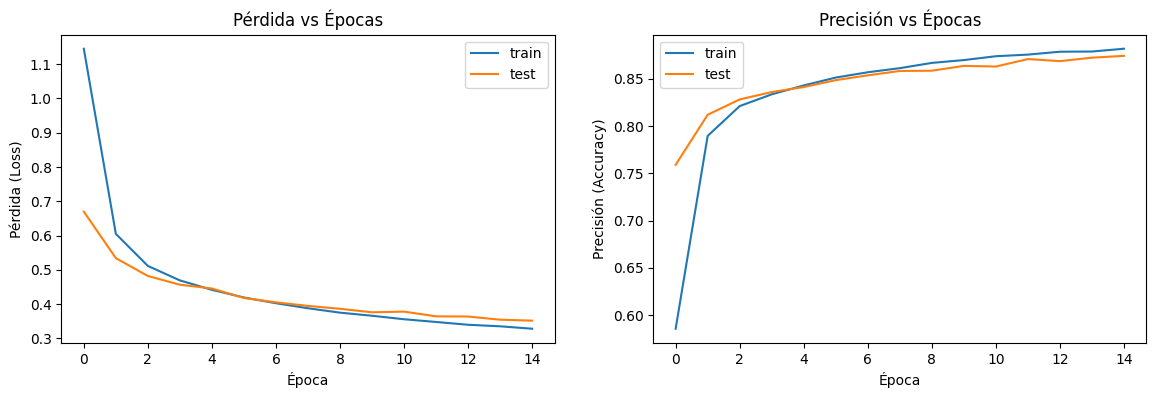

In [116]:
def show_fashion_results(model, log):
    loss, acc = model.evaluate(x_test_fashion, y_test_fashion, batch_size=512, verbose=False)
    print(f'Loss en Test     = {loss:.4f}')
    print(f'Accuracy en Test = {acc:.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(log.history['loss'], label='train')
    axes[0].plot(log.history['val_loss'], label='test')
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Pérdida (Loss)')
    axes[0].set_title('Pérdida vs Épocas')
    axes[0].legend()

    axes[1].plot(log.history['accuracy'], label='train')
    axes[1].plot(log.history['val_accuracy'], label='test')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Precisión (Accuracy)')
    axes[1].set_title('Precisión vs Épocas')
    axes[1].legend()

    plt.show()

show_fashion_results(fashion_model, history_fashion)